# Train — ResNet-50

Trains and evaluates ResNet-50 with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet50"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet50"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-50: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-50: micro batch = 16, accumulation steps = 1 (effective batch size ≈ 16, target = 16)
Train: 1348 | Val: 323 | Test: 856


## Model

In [3]:
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-50] Epoch   1/100 | LR: 1.33e-04 | train loss 0.9270 acc 0.613 | val loss 0.6852 acc 0.697 *


[ResNet-50] Epoch   2/100 | LR: 1.33e-04 | train loss 0.6138 acc 0.711 | val loss 0.6070 acc 0.731 *


[ResNet-50] Epoch   3/100 | LR: 1.33e-04 | train loss 0.5142 acc 0.758 | val loss 0.7096 acc 0.594


[ResNet-50] Epoch   4/100 | LR: 1.33e-04 | train loss 0.4260 acc 0.803 | val loss 0.4567 acc 0.820 *


[ResNet-50] Epoch   5/100 | LR: 1.33e-04 | train loss 0.3740 acc 0.837 | val loss 0.7637 acc 0.740


...

[ResNet-50] Epoch  10/100 | LR: 1.33e-04 | train loss 0.2033 acc 0.912 | val loss 0.6390 acc 0.789


[ResNet-50] Epoch  11/100 | LR: 1.33e-04 | train loss 0.2242 acc 0.904 | val loss 0.7835 acc 0.783


[ResNet-50] Epoch  12/100 | LR: 1.33e-04 | train loss 0.1709 acc 0.914 | val loss 0.5371 acc 0.820


[ResNet-50] Epoch  13/100 | LR: 1.33e-05 | train loss 0.1460 acc 0.935 | val loss 0.5152 acc 0.839


[ResNet-50] Epoch  14/100 | LR: 1.33e-05 | train loss 0.0881 acc 0.964 | val loss 0.5117 acc 0.851

[ResNet-50] No val loss improvement for 10 epochs, stopping at epoch 14.

[ResNet-50] Restored best checkpoint (val loss = 0.4567)


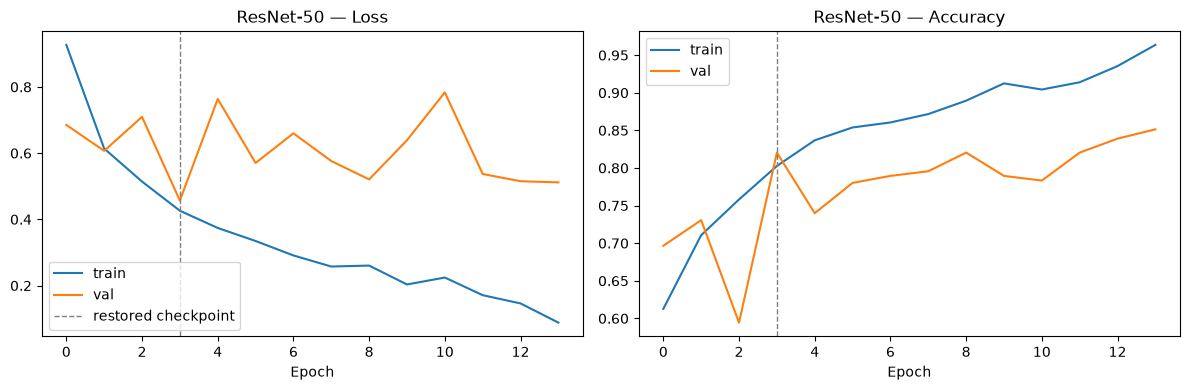

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-50", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-50")

## Evaluate on the test set

[ResNet-50] Test accuracy: 0.761


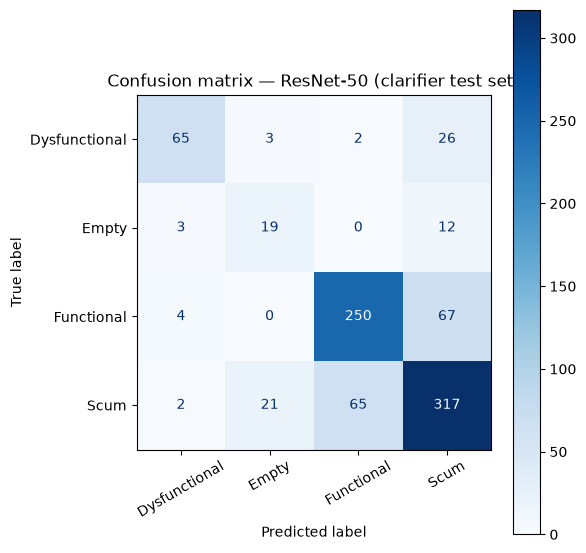

               precision    recall  f1-score   support

Dysfunctional      0.878     0.677     0.765        96
        Empty      0.442     0.559     0.494        34
   Functional      0.789     0.779     0.784       321
         Scum      0.751     0.783     0.767       405

     accuracy                          0.761       856
    macro avg      0.715     0.699     0.702       856
 weighted avg      0.767     0.761     0.762       856



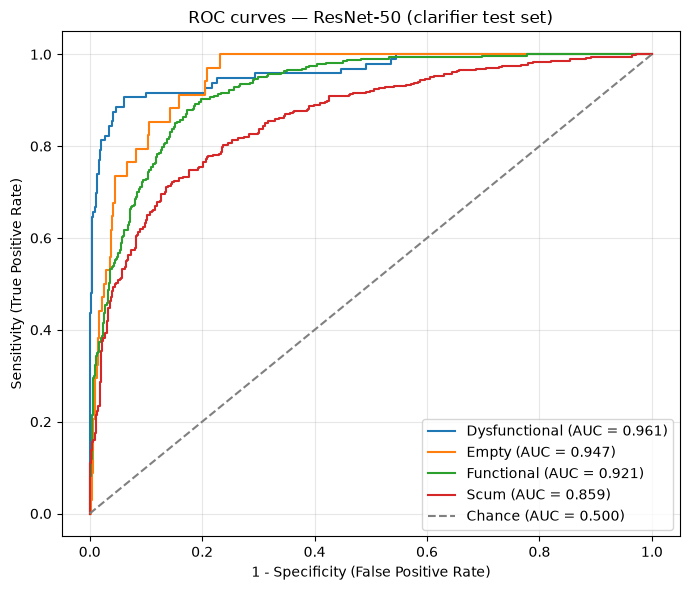

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.961
  Empty          : 0.947
  Functional     : 0.921
  Scum           : 0.859

Mean AUC (over 4/4 classes with test examples): 0.922


(np.float64(0.7605140186915887),
 {'Dysfunctional': 0.9607867324561403,
  'Empty': 0.9469371690281952,
  'Functional': 0.9212332954843218,
  'Scum': 0.8592537844570365})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-50", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-50", "resnet50")

Saved results to ../results/clarifier_aug/results_clarifier_resnet50_chronological.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet50_chronological.pt
